# Mini-Project 2: Uganda Tax Engine

**What this is.** An extensible, testable calculator for the taxes URA
administers: PAYE, NSSF, Local Service Tax, VAT and corporate income tax,
plus withholding and rental income tax as the extension.

**Where the code lives.** `src/tax/`: `money.py` (the `Money` value object),
`core.py` (the abstract `Tax`, `TaxContext` and `TaxResult`), `paye.py`,
`payroll.py`, `vat.py` and `corporate.py`. This notebook exercises them.

**Rates used.** The baseline table in the brief, cross-checked against the
Income Tax Act Cap 340 Third Schedule as published by URA. Every schedule
carries its own `source` string, printed below, and schedules are
effective-dated so a figure can always be traced to the rules in force on
the day it was calculated.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import datetime as dt
from decimal import Decimal

import pandas as pd
import matplotlib.pyplot as plt

from src.weather.display import PALETTE, house_style, save
from src.tax.core import Residency, Tax, TaxContext, TaxResult
from src.tax.corporate import (CorporateIncomeTax, Expense, PaymentType,
                               RentalIncomeTax, WithholdingTax, WITHHOLDING_RATES)
from src.tax.errors import (InvalidIncomeError, InvalidRateError,
                            NoScheduleForDateError, TaxError, UnknownSupplyError)
from src.tax.money import Money, float_is_unsafe
from src.tax.paye import PayeTax, SCHEDULES, ScheduleRegistry
from src.tax.payroll import (LocalServiceTax, NssfContribution, PayeDeduction,
                             PayrollRun, lst_for_income)
from src.tax.vat import Invoice, SupplyType, VatTax

house_style()
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

PERIOD = dt.date(2026, 7, 1)
print(f"calculating for the month beginning {PERIOD.isoformat()}")

calculating for the month beginning 2026-07-01


## The rate schedules, and their sources

Rates are data, not constants buried in a function. Each schedule records
where it came from and when it took effect.

In [2]:
for schedule in SCHEDULES:
    print(f"{schedule}")
    for band in schedule:
        print(f"    {band}")
    print(f"    plus {schedule.surcharge_rate:.0%} on income above "
          f"{schedule.surcharge_threshold}")
    print(f"    source: {schedule.source}\n")

resident schedule from 2012-07-01 (4 bands)
    UGX 0 to UGX 335,000 at 0%
    UGX 335,000 to UGX 410,000 at 20%
    UGX 410,000 to UGX 485,000 at 25%
    UGX 485,000 upwards at 30%
    plus 10% on income above UGX 10,000,000
    source: URA monthly PAYE rates for resident individuals, as set out in the assignment brief and published at ura.go.ug (Income Tax Act Cap 340, Third Schedule). Rates confirmed against the brief's baseline table.

non-resident schedule from 2012-07-01 (4 bands)
    UGX 0 to UGX 335,000 at 10%
    UGX 335,000 to UGX 410,000 at 20%
    UGX 410,000 to UGX 485,000 at 25%
    UGX 485,000 upwards at 30%
    plus 10% on income above UGX 10,000,000
    source: URA monthly PAYE rates for non-resident individuals: no nil band, 10% from the first shilling (Income Tax Act Cap 340, Third Schedule Part II). Not supplied in the brief; sourced from URA's published monthly tables.



## Why `float` is unsafe here

The brief asks for a concrete failing example. There are three, and each one
below was checked to actually fail rather than being asserted.

In [3]:
evidence = float_is_unsafe()

print("1. ROUNDING GOES THE WRONG WAY")
print(f"   round(2.675, 2)  -> {evidence['round_float']}")
print(f"   the exact answer -> {evidence['round_exact']}")
print(f"   wrong?           -> {evidence['round_wrong']}")
print(f"   because 2.675 is actually stored as:")
print(f"     {evidence['round_stored_as']}")
print("   The stored double sits just BELOW 2.675, so round-half-up rounds it")
print("   DOWN. For a tax figure that is a wrong shilling with no diagnosable")
print("   cause: the decimal digits say .675 and the answer says .67.")

print("\n2. ADDITION IS NOT ASSOCIATIVE")
print(f"   (0.1 + 0.2) + 0.3 = {evidence['assoc_left']!r}")
print(f"   0.1 + (0.2 + 0.3) = {evidence['assoc_right']!r}")
print(f"   equal?             {evidence['assoc_equal']}")
print("   A payslip sums several deductions. In float the total depends on the")
print("   ORDER they are added, so two correct implementations can disagree and")
print("   neither is wrong.")

print("\n3. ERROR ACCUMULATES")
print(f"   {evidence['repeats']:,} applications of a rate:")
print(f"   float   -> {evidence['float_total']!r}")
print(f"   Decimal -> {evidence['decimal_total']}")
print(f"   drift   -> {evidence['drift']} UGX")

print(f"\n   and the classic: {evidence['classic']}  ({evidence['classic_value']})")

1. ROUNDING GOES THE WRONG WAY
   round(2.675, 2)  -> 2.67
   the exact answer -> 2.68
   wrong?           -> True
   because 2.675 is actually stored as:
     2.67499999999999982236431605997495353221893310546875
   The stored double sits just BELOW 2.675, so round-half-up rounds it
   DOWN. For a tax figure that is a wrong shilling with no diagnosable
   cause: the decimal digits say .675 and the answer says .67.

2. ADDITION IS NOT ASSOCIATIVE
   (0.1 + 0.2) + 0.3 = 0.6000000000000001
   0.1 + (0.2 + 0.3) = 0.6
   equal?             False
   A payslip sums several deductions. In float the total depends on the
   ORDER they are added, so two correct implementations can disagree and
   neither is wrong.

3. ERROR ACCUMULATES
   10,000 applications of a rate:
   float   -> 670002000.0000274
   Decimal -> 670002000.0
   drift   -> 0.0000274 UGX

   and the classic: 0.1 + 0.2 == 0.3 is False  (0.30000000000000004)


In [4]:
print("So Money refuses float at the door, loudly:")
for attempt, label in ((lambda: Money(335000.50), "Money(335000.50)"),
                       (lambda: Money("1000") * 0.3, "Money('1000') * 0.3"),
                       (lambda: Money("1000") * Money("2"), "Money * Money")):
    try:
        attempt()
        print(f"  {label:<24} -> unexpectedly allowed")
    except TypeError as problem:
        print(f"  {label:<24} -> TypeError: {str(problem)[:70]}")

print("\nand accepts only exact representations:")
print(f"  Money(335000) == Money('335000') == Money(Decimal('335000')): "
      f"{Money(335000) == Money('335000') == Money(Decimal('335000'))}")

So Money refuses float at the door, loudly:
  Money(335000.50)         -> TypeError: Money refuses float: 0.1 + 0.2 != 0.3 in binary floating point, and th
  Money('1000') * 0.3      -> TypeError: Money refuses float rates; use Decimal('0.3')
  Money * Money            -> TypeError: multiplying Money by Money is meaningless

and accepts only exact representations:
  Money(335000) == Money('335000') == Money(Decimal('335000')): True


## 1. PAYE calculator

### The band edges the brief names

In [5]:
paye = PayeTax()
edges = [335_000, 335_001, 410_000, 485_000, 10_000_000, 10_000_001]
rows = []
for gross in edges:
    result = paye.calculate(TaxContext(period=PERIOD, gross=Money(gross)))
    rows.append({"monthly gross": gross,
                 "PAYE": int(result.payable.amount),
                 "effective rate": float(result.effective_rate)})
boundary = pd.DataFrame(rows).set_index("monthly gross")
boundary["effective rate"] = boundary["effective rate"].map("{:.4%}".format)
boundary

,PAYE,effective rate
monthly gross,,
335000,0,0.0000%
335001,0,0.0000%
410000,15000,3.6585%
485000,33750,6.9588%
10000000,2888250,28.8825%
10000001,2888250,28.8825%


Two of these deserve a word.

**335,001 charges nothing.** Twenty per cent of one shilling is 0.2, which
rounds to zero. That is correct, not a bug: the nil band ends at 335,000 and
the charge grows continuously from there.

**10,000,001 charges the same as 10,000,000.** The additional 10% applies to
one shilling of excess, which is 10 cents, which rounds away. Again correct —
and the check that matters is that the *marginal rate* above the threshold
really is 40%, not 30%.

In [6]:
at_threshold = paye.calculate(TaxContext(period=PERIOD,
                                         gross=Money(10_000_000))).payable
above = paye.calculate(TaxContext(period=PERIOD, gross=Money(11_000_000))).payable
extra = above - at_threshold
print(f"tax at 10,000,000      : {at_threshold}")
print(f"tax at 11,000,000      : {above}")
print(f"extra on the 1,000,000 : {extra}")
print(f"marginal rate          : {extra.amount / 1_000_000:.0%}  "
      f"(30% band + 10% additional charge)")
assert extra == Money("400000")

tax at 10,000,000      : UGX 2,888,250
tax at 11,000,000      : UGX 3,288,250
extra on the 1,000,000 : UGX 400,000
marginal rate          : 40%  (30% band + 10% additional charge)


### The arithmetic, shown

In [7]:
print(paye.calculate(TaxContext(period=PERIOD, gross=Money(12_000_000))).explain())

PAYE on UGX 12,000,000
  band UGX 0 to UGX 335,000 at 0%: UGX 335,000 x 0.00 = UGX 0
  band UGX 335,000 to UGX 410,000 at 20%: UGX 75,000 x 0.20 = UGX 15,000
  band UGX 410,000 to UGX 485,000 at 25%: UGX 75,000 x 0.25 = UGX 18,750
  band UGX 485,000 upwards at 30%: UGX 11,515,000 x 0.30 = UGX 3,454,500
  additional charge above UGX 10,000,000: UGX 2,000,000 x 0.10 = UGX 200,000
  = UGX 3,688,250  (effective rate 30.74%)
  note: resident schedule from 2012-07-01 (4 bands)
  note: URA monthly PAYE rates for resident individuals, as set out in the assignment brief and published at ura.go.ug (Income Tax Act Cap 340, Third Schedule). Rates confirmed against the brief's baseline table.


### Resident against non-resident

The brief supplies only the resident schedule. The non-resident one comes
from URA's published monthly tables: no nil band, and 10% from the first
shilling. Both carry the additional charge above 10,000,000.

In [8]:
incomes = [200_000, 335_000, 500_000, 1_000_000, 3_000_000, 12_000_000]
comparison = pd.DataFrame({
    "resident": [int(paye.calculate(TaxContext(period=PERIOD, gross=Money(g)))
                     .payable.amount) for g in incomes],
    "non-resident": [int(paye.calculate(TaxContext(
        period=PERIOD, gross=Money(g),
        residency=Residency.NON_RESIDENT)).payable.amount) for g in incomes],
}, index=incomes)
comparison.index.name = "monthly gross"
comparison["difference"] = comparison["non-resident"] - comparison["resident"]
comparison

,resident,non-resident,difference
monthly gross,,,
200000,0,20000,20000
335000,0,33500,33500
500000,38250,71750,33500
1000000,188250,221750,33500
3000000,788250,821750,33500
12000000,3688250,3721750,33500


saved: mp2_paye_rates.png


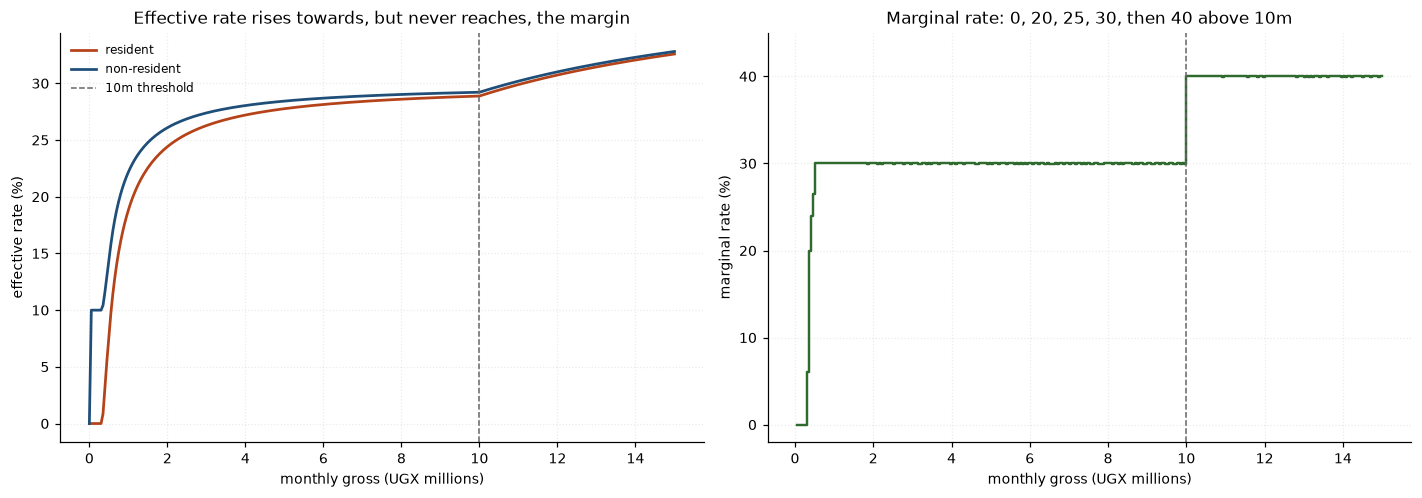

In [9]:
fine = list(range(0, 15_000_001, 50_000))
curves = {}
for status in (Residency.RESIDENT, Residency.NON_RESIDENT):
    curves[status] = [float(paye.calculate(TaxContext(
        period=PERIOD, gross=Money(g), residency=status)).effective_rate)
        for g in fine]

figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for index, (status, rates) in enumerate(curves.items()):
    axes[0].plot([g / 1e6 for g in fine], [r * 100 for r in rates],
                 color=PALETTE[index], lw=1.8, label=status)
axes[0].axvline(10, color="0.4", ls="--", lw=1, label="10m threshold")
axes[0].set_xlabel("monthly gross (UGX millions)")
axes[0].set_ylabel("effective rate (%)")
axes[0].set_title("Effective rate rises towards, but never reaches, the margin")
axes[0].legend(fontsize=8)

marginal = [(curves[Residency.RESIDENT][i + 1] * fine[i + 1]
             - curves[Residency.RESIDENT][i] * fine[i]) / 50_000
            for i in range(len(fine) - 1)]
axes[1].step([g / 1e6 for g in fine[1:]], [m * 100 for m in marginal],
             color=PALETTE[2], lw=1.6, where="pre")
axes[1].axvline(10, color="0.4", ls="--", lw=1)
axes[1].set_xlabel("monthly gross (UGX millions)")
axes[1].set_ylabel("marginal rate (%)")
axes[1].set_title("Marginal rate: 0, 20, 25, 30, then 40 above 10m")
axes[1].set_ylim(-2, 45)

figure.tight_layout()
print("saved:", save(figure, "mp2_paye_rates.png").name)
plt.show()

### Effective-dated schedules

`NoScheduleForDateError` exists because rates change. Asking for a date no
schedule covers is a gap in the data, and the engine says so instead of
quietly applying whichever schedule happens to be nearest.

In [10]:
try:
    paye.calculate(TaxContext(period=dt.date(2000, 1, 1), gross=Money("500000")))
except NoScheduleForDateError as problem:
    print(f"{type(problem).__name__}: {problem}")

print("\nAdding a future schedule is a data change, not a code change:")
registry = ScheduleRegistry()
print(f"  {registry!r}")
print(f"  schedule in force on 2026-07-01: "
      f"{registry.for_date(PERIOD, Residency.RESIDENT)}")

NoScheduleForDateError: no tax schedule for resident covers 2000-01-01; schedules on file: 2012-07-01

Adding a future schedule is a data change, not a code change:
  ScheduleRegistry({'resident': 1, 'non-resident': 1})
  schedule in force on 2026-07-01: resident schedule from 2012-07-01 (4 bands)


## 2. Payroll pipeline

### The order of deductions, and the justification

| Step | Line | Charged before PAYE? | Reduces net pay? |
|---|---|---|---|
| 1 | Local Service Tax | **yes** | yes |
| 2 | PAYE | – | yes |
| 3 | NSSF employee 5% | no | yes |
| – | NSSF employer 10% | no | **no** |

**Why this order.** LST is an allowable deduction against employment income,
so PAYE is charged on gross *less* LST — the brief states this directly and
it matches the Local Governments Act treatment. NSSF is the step most often
got wrong: the employee's 5% is computed on **gross**, and Uganda does *not*
allow it as a deduction against employment income the way several
neighbouring jurisdictions do. PAYE and NSSF are therefore charged on
overlapping bases and neither reduces the other. The employer's 10% never
touches net pay at all; it is a cost of employment borne on top of the wage,
so it is reported separately rather than deducted.

In [11]:
run = PayrollRun()
run.order()

,step,line,charged before PAYE,reduces net pay
0,1,Local Service Tax,True,True
1,2,PAYE,False,True
2,3,NSSF employee (5%),False,True


In [12]:
ctx = TaxContext(period=PERIOD, gross=Money("2500000"),
                 allowances=Money("300000"))
slip = run.run(ctx)
print(slip.explain())

Payroll for 2026-07-01
  Gross pay                                2800000
  less Local Service Tax                    -25000
  less PAYE                                -720750
  less NSSF employee (5%)                  -140000
  Net pay                                  1914250
  (take-home 68.37% of gross)
  Employer total cost                      3080000


In [13]:
slip.to_frame()

,line,amount_ugx
0,Gross pay,2800000
1,Local Service Tax,-25000
2,PAYE,-720750
3,NSSF employee (5%),-140000
4,Net pay,1914250
5,Employer NSSF (not deducted),280000


### What the ordering is worth

Applying LST before PAYE instead of after is not a rounding detail.

In [14]:
without_lst = PayrollRun(deductions=[PayeDeduction(), NssfContribution()]).run(ctx)
print(f"PAYE with LST deducted first : {slip.paye.payable}")
print(f"PAYE if LST were ignored     : {without_lst.paye.payable}")
print(f"difference                   : "
      f"{without_lst.paye.payable - slip.paye.payable}")
print(f"\nLST itself was              : {dict(slip.lines)['Local Service Tax']}")
print("At the 30% marginal rate, deducting LST first returns 30% of it through")
print("a lower PAYE charge. Getting the order wrong overstates the tax.")

PAYE with LST deducted first : UGX 720,750
PAYE if LST were ignored     : UGX 728,250
difference                   : UGX 7,500

LST itself was              : UGX 25,000
At the 30% marginal rate, deducting LST first returns 30% of it through
a lower PAYE charge. Getting the order wrong overstates the tax.


In [15]:
grosses = [500_000, 1_000_000, 2_000_000, 5_000_000, 12_000_000]
ladder = []
for gross in grosses:
    slip_n = run.run(TaxContext(period=PERIOD, gross=Money(gross)))
    lines = dict(slip_n.lines)
    ladder.append({
        "gross": gross,
        "LST": int(lines["Local Service Tax"].amount),
        "PAYE": int(lines["PAYE"].amount),
        "NSSF 5%": int(lines["NSSF employee (5%)"].amount),
        "net pay": int(slip_n.net.amount),
        "take-home": float(slip_n.take_home_rate),
        "employer cost": int(slip_n.employer_cost.amount),
    })
ladder = pd.DataFrame(ladder).set_index("gross")
ladder["take-home"] = ladder["take-home"].map("{:.1%}".format)
ladder

,LST,PAYE,NSSF 5%,net pay,take-home,employer cost
gross,,,,,,
500000,10000,35250,25000,429750,86.0%,550000
1000000,15000,183750,50000,751250,75.1%,1100000
2000000,25000,480750,100000,1394250,69.7%,2200000
5000000,25000,1380750,250000,3344250,66.9%,5500000
12000000,25000,3678250,600000,7696750,64.1%,13200000


## 3. VAT module

### The distinction that matters: zero-rated is not exempt

Both produce no output VAT, so they look identical on a sales report. They
are not. A zero-rated supply is a **taxable** supply charged at 0%, so input
VAT incurred in making it stays recoverable. An exempt supply is outside the
VAT net, so input VAT attributable to it is **blocked** and becomes a real
cost. Treating them the same way always overstates the refund.

In [16]:
pd.DataFrame([{"supply": str(s), "output rate": f"{s.output_rate:.0%}",
               "input VAT recoverable": s.input_recoverable}
              for s in SupplyType])

,supply,output rate,input VAT recoverable
0,standard-rated,18%,True
1,zero-rated,0%,True
2,exempt,0%,False


In [17]:
invoices = [
    Invoice("INV-001 export of coffee", Money("4000000"), SupplyType.ZERO_RATED),
    Invoice("INV-002 local sales", Money("10000000"), SupplyType.STANDARD),
    Invoice("INV-003 financial services", Money("3000000"), SupplyType.EXEMPT),
    Invoice("PUR-010 packaging", Money("5000000"), SupplyType.STANDARD,
            is_purchase=True),
    Invoice("PUR-011 export logistics", Money("2000000"), SupplyType.ZERO_RATED,
            is_purchase=True, vat_charged=Money("360000")),
    Invoice("PUR-012 branch costs", Money("1500000"), SupplyType.EXEMPT,
            is_purchase=True, vat_charged=Money("270000")),
]
for invoice in invoices:
    print(f"  {invoice}")

  INV-001 export of coffee (sale, zero-rated): UGX 4,000,000 + UGX 0 VAT
  INV-002 local sales (sale, standard-rated): UGX 10,000,000 + UGX 1,800,000 VAT
  INV-003 financial services (sale, exempt): UGX 3,000,000 + UGX 0 VAT
  PUR-010 packaging (purchase, standard-rated): UGX 5,000,000 + UGX 900,000 VAT
  PUR-011 export logistics (purchase, zero-rated): UGX 2,000,000 + UGX 360,000 VAT
  PUR-012 branch costs (purchase, exempt): UGX 1,500,000 + UGX 270,000 VAT


In [18]:
vat = VatTax()
completed = vat.prepare_return(invoices)
print(completed.explain())
print()
completed.by_supply

  Output VAT on sales                         1800000
  less recoverable input VAT                 -1260000
  = net VAT payable                           540000
  (input VAT blocked as attributable to exempt supplies: UGX 270,000)



,supply,net sales,output VAT,input VAT,input recoverable
0,standard-rated,10000000,1800000,900000,True
1,zero-rated,4000000,0,360000,True
2,exempt,3000000,0,270000,False


In [19]:
print("If exempt supplies were wrongly treated as zero-rated, the blocked")
print(f"input VAT of {completed.input_vat_blocked} would have been reclaimed,")
print(f"turning a payment of {completed.net_payable} into")
print(f"{completed.net_payable - completed.input_vat_blocked} — an understatement")
print("of the liability, and the kind of error an audit finds.")

If exempt supplies were wrongly treated as zero-rated, the blocked
input VAT of UGX 270,000 would have been reclaimed,
turning a payment of UGX 540,000 into
UGX 270,000 — an understatement
of the liability, and the kind of error an audit finds.


## 4. Corporate income tax

Chargeable income is revenue less **allowable** deductions. The word is
doing the work: a disallowed expense still reduces accounting profit while
leaving taxable profit untouched, so the two figures diverge and the
difference has to be added back.

In [20]:
expenses = [
    Expense("staff costs", Money("40000000")),
    Expense("rent", Money("12000000")),
    Expense("depreciation (accounting)", Money("8000000"), allowable=False),
    Expense("URA penalties", Money("2000000"), allowable=False),
]
for expense in expenses:
    print(f"  {expense}")

cit = CorporateIncomeTax()
result = cit.calculate(TaxContext(period=PERIOD, revenue=Money("100000000"),
                                  extras={"expenses": expenses}))
print()
print(result.explain())

  staff costs: UGX 40,000,000 (allowable)
  rent: UGX 12,000,000 (allowable)
  depreciation (accounting): UGX 8,000,000 (DISALLOWED)
  URA penalties: UGX 2,000,000 (DISALLOWED)

Corporate income tax on UGX 48,000,000
  revenue less allowable deductions: UGX 48,000,000 x 0.30 = UGX 14,400,000
  = UGX 14,400,000  (effective rate 30.00%)
  note: UGX 10,000,000 of expenses disallowed and added back


In [21]:
accounting_profit = Money("100000000")
for expense in expenses:
    accounting_profit = accounting_profit - expense.amount
print(f"accounting profit : {accounting_profit}")
print(f"chargeable income : {result.chargeable}")
print(f"difference        : {result.chargeable - accounting_profit} "
      f"(the disallowed expenses, added back)")

accounting profit : UGX 38,000,000
chargeable income : UGX 48,000,000
difference        : UGX 10,000,000 (the disallowed expenses, added back)


In [22]:
print("a loss produces no charge, not a negative one:")
loss = cit.calculate(TaxContext(period=PERIOD, revenue=Money("10000000"),
                                deductions=Money("25000000")))
print(f"  chargeable {loss.chargeable}, payable {loss.payable}")
print(f"  note: {loss.notes[-1]}")

a loss produces no charge, not a negative one:
  chargeable UGX 0, payable UGX 0
  note: a loss carries forward; this period's charge is nil


## Extension A: withholding tax and rental income tax

The brief offers two extensions; this build implements **option A**.

In [23]:
pd.DataFrame([{"payment type": str(kind), "resident rate": f"{rate:.0%}"}
              for kind, rate in WITHHOLDING_RATES.items()])

,payment type,resident rate
0,goods and services,6%
1,professional fees,6%
2,dividends,15%
3,interest,15%
4,royalties,15%
5,rent paid to a resident,10%


In [24]:
print("withholding on a professional fee:")
print(WithholdingTax(PaymentType.PROFESSIONAL_FEES).calculate(
    TaxContext(period=PERIOD, revenue=Money("5000000"))).explain())

print("\nand the goods-and-services threshold in action:")
for amount in ("500000", "2000000"):
    outcome = WithholdingTax(PaymentType.GOODS_AND_SERVICES).calculate(
        TaxContext(period=PERIOD, revenue=Money(amount)))
    print(f"  payment {Money(amount)} -> withheld {outcome.payable}")

withholding on a professional fee:
Withholding tax on UGX 5,000,000
  withholding on professional fees: UGX 5,000,000 x 0.06 = UGX 300,000
  = UGX 300,000  (effective rate 6.00%)
  note: professional fees withheld at 6%
  note: resident rates only; non-resident and treaty rates differ

and the goods-and-services threshold in action:
  payment UGX 500,000 -> withheld UGX 0
  payment UGX 2,000,000 -> withheld UGX 120,000


In [25]:
rental = RentalIncomeTax()
rents = ["2000000", "3500000", "10000000", "20000000", "50000000"]
pd.DataFrame([{
    "annual rent": int(Money(r).amount),
    "chargeable": int(rental.calculate(
        TaxContext(period=PERIOD, revenue=Money(r))).chargeable.amount),
    "tax": int(rental.calculate(
        TaxContext(period=PERIOD, revenue=Money(r))).payable.amount),
} for r in rents]).set_index("annual rent")

,chargeable,tax
annual rent,,
2000000,0,0
3500000,0,0
10000000,5180000,621600
20000000,13180000,1581600
50000000,37180000,4461600


In [26]:
print(rental.calculate(TaxContext(period=PERIOD,
                                  revenue=Money("20000000"))).explain())

Rental income tax on UGX 13,180,000
  expense allowance at 20%: UGX 20,000,000 x 0.20 = UGX 4,000,000
  less threshold UGX 2,820,000: UGX 16,000,000 x 1 = UGX 13,180,000
  rental income tax: UGX 13,180,000 x 0.12 = UGX 1,581,600
  = UGX 1,581,600  (effective rate 12.00%)
  note: individual landlord: 20% allowance, UGX 2,820,000 threshold, 12% rate


## One abstraction, five taxes

Every tax above satisfies the same contract: `calculate(ctx) -> TaxResult`.
That is what lets a report loop over them rather than special-casing each.

In [27]:
shared = TaxContext(period=PERIOD, gross=Money("3000000"),
                    revenue=Money("50000000"), deductions=Money("20000000"),
                    invoices=tuple(invoices))
summary = []
for tax in (PayeTax(), VatTax(), CorporateIncomeTax(),
            WithholdingTax(PaymentType.PROFESSIONAL_FEES), RentalIncomeTax()):
    outcome = tax.calculate(shared)
    summary.append({"tax": outcome.tax,
                    "chargeable": int(outcome.chargeable.amount),
                    "payable": int(outcome.payable.amount),
                    "effective rate": f"{outcome.effective_rate:.2%}"})
pd.DataFrame(summary).set_index("tax")

,chargeable,payable,effective rate
tax,,,
PAYE,3000000,788250,26.28%
VAT,10000000,540000,5.40%
Corporate income tax,30000000,9000000,30.00%
Withholding tax,50000000,3000000,6.00%
Rental income tax,37180000,4461600,12.00%


## Validation: nothing fails silently

In [28]:
checks = [
    ("negative pay", lambda: TaxContext(period=PERIOD, gross=Money("-1"))),
    ("unknown residency", lambda: TaxContext(period=PERIOD, gross=Money("1"),
                                             residency="martian")),
    ("a float rate", lambda: VatTax(rate=0.18)),
    ("an unknown supply type", lambda: Invoice("X", Money("100"),
                                               supply="standard")),
    ("a negative expense", lambda: Expense("odd", Money("-1"))),
    ("an uncovered date", lambda: PayeTax().calculate(
        TaxContext(period=dt.date(1999, 1, 1), gross=Money("500000")))),
]
for label, attempt in checks:
    try:
        attempt()
        print(f"  {label:<24} -> NOT CAUGHT")
    except (TaxError, ValueError, TypeError) as problem:
        print(f"  {label:<24} -> {type(problem).__name__}: "
              f"{str(problem)[:60]}")

  negative pay             -> InvalidIncomeError: gross cannot be negative: got UGX -1
  unknown residency        -> ValueError: residency must be one of ['non-resident', 'resident'], got '
  a float rate             -> InvalidRateError: the VAT rate must be a Decimal: got 0.18
  an unknown supply type   -> UnknownSupplyError: unknown supply type 'standard'
  a negative expense       -> InvalidIncomeError: an expense cannot be negative: got UGX -1
  an uncovered date        -> NoScheduleForDateError: no tax schedule for resident covers 1999-01-01; schedules on


## Discussion

### 1. Why is `float` unsafe for tax computation?

Because binary floating point cannot represent most decimal fractions, and
tax is defined in decimal. The demonstration above shows three distinct
consequences, and the first is the one that would actually reach a payslip:
`round(2.675, 2)` returns `2.67`, because the nearest double to 2.675 is
fractionally *below* it. A round-half-up rule applied to a float therefore
rounds half *down* whenever the stored value happens to fall on the low side,
and which way it falls cannot be predicted from the decimal digits. The
result is a figure that is wrong by one unit, inconsistently, with no
diagnosable cause — the worst possible failure mode in a system whose output
a person is legally obliged to pay.

The second consequence is subtler and affects the payroll pipeline directly.
Float addition is not associative: `(0.1 + 0.2) + 0.3` and
`0.1 + (0.2 + 0.3)` are different doubles. A payslip sums LST, PAYE and NSSF;
in float, the total would depend on the order the lines were added, so two
faithful implementations of the same documented rules could disagree and
neither would be at fault. The third is accumulation: applying a rate
repeatedly drifts from the exact answer, and the drift grows with the number
of operations, so the error is worst in exactly the high-volume payroll runs
where it is least likely to be spotted.

`Decimal` fixes all three because it stores decimal digits and lets the
rounding rule be stated explicitly and not inherited from the hardware.
`Money` therefore refuses `float` at construction and refuses `float` rates
in multiplication, raising `TypeError` with an explanation. Refusing is
better than coercing: `Money(335000.50)` could be silently accepted as
`Money('335000')`, and a system that quietly discards half a shilling is
worse than one that stops.

### 2. Where is inheritance justified here, and where was it deliberately avoided?

**Justified: the `Tax` hierarchy.** `PayeTax`, `VatTax`,
`CorporateIncomeTax`, `WithholdingTax` and `RentalIncomeTax` all subclass
`Tax`. What they share is not behaviour but a *contract*:
`calculate(ctx) -> TaxResult`. That is exactly the case inheritance exists
for — the base class holds no arithmetic at all, because the five do
genuinely different things (one walks progressive bands, one nets two running
totals, three apply a flat rate to different bases). The payoff is concrete
and visible in the cell above: a report can loop over all five, and the
payroll pipeline can accept any `Tax` for its PAYE step, because the type
guarantees the shape of the answer.

**Justified: `Deduction`.** The payroll lines share a real contract —
"given a context and a running base, how much do you take" — and the pipeline
applies them in order without knowing what any of them is. Adding a new
statutory deduction means adding a class, not editing the run method.

**Deliberately avoided: `RentalIncomeTax` does not extend `PayeTax`.** The
temptation is obvious, since both charge an individual on a progressive-ish
basis with a threshold, and a quick `class RentalIncomeTax(PayeTax)` would
have reused the band machinery. It would also have been wrong. Rental income
is a separate chargeable head under the Act, not another employment band: its
allowance, threshold and rate are set independently, and a future change to
the PAYE bands must not silently move the rental calculation. Inheriting
would have created exactly that coupling, for the sake of code that is four
lines long.

**Deliberately avoided: `ReplayClient` does not extend `ApiClient`.** In the
weather project the same judgement arises. The two share an interface
(`get_json`) but no implementation — one does HTTP with retries, the other
reads files. Subclassing would have inherited a `requests.Session`, a retry
policy and a timeout that the replay client has no use for, and would have
invited someone to call an inherited method that makes a real request from
what is supposed to be an offline object. Duck typing gives the substitution
without the baggage.

**Deliberately avoided: `Money` does not extend `Decimal`.** Subclassing
`Decimal` would have made `Money` arithmetic work "for free", and would have
meant `Money * Money` silently returning a `Decimal`, `Money + 0.5`
accepting a float through the inherited operator, and the rounding policy
being bypassable by any inherited method that returns a bare `Decimal`.
Composition — holding a `Decimal` and exposing only the operations that make
sense for money — is what allows the type to *refuse* things, and refusing is
the entire point of the class.

The pattern across all four decisions is the same: inheritance where the
subtypes owe the same promise to a caller, composition or duck typing where
they merely happen to need similar code.

## Testing

The suite in `tests/test_tax.py` covers the boundary cases the brief lists
explicitly and the property-based checks it asks for with `hypothesis`:
that tax is non-negative, monotonic in income, and never exceeds income.
The cell below re-runs the three properties inline over a wide range.

In [29]:
import random

random.seed(2026)
probe = sorted(random.sample(range(0, 60_000_000), 400) + edges)

non_negative = all(not paye.calculate(
    TaxContext(period=PERIOD, gross=Money(g))).payable.is_negative() for g in probe)
never_exceeds = all(paye.calculate(
    TaxContext(period=PERIOD, gross=Money(g))).payable <= Money(g) for g in probe)
charges = [paye.calculate(TaxContext(period=PERIOD, gross=Money(g))).payable
           for g in probe]
monotonic = all(b >= a for a, b in zip(charges, charges[1:]))

print(f"over {len(probe)} incomes from 0 to 60,000,000:")
print(f"  tax is never negative   : {non_negative}")
print(f"  tax never exceeds income: {never_exceeds}")
print(f"  tax is monotonic        : {monotonic}")
assert non_negative and never_exceeds and monotonic
print("\n(hypothesis checks the same three properties over generated inputs in")
print(" tests/test_tax.py, which is stricter than this fixed sample)")

over 406 incomes from 0 to 60,000,000:
  tax is never negative   : True
  tax never exceeds income: True
  tax is monotonic        : True

(hypothesis checks the same three properties over generated inputs in
 tests/test_tax.py, which is stricter than this fixed sample)
